# Customer Churn Prediction — Machine Learning & Artificial Neural Network

**Notebook reconstructed from the practical implementation in the academic report** *Rapport_Academique_Churn_Prediction_ML_ANN* (Chapter 3, sections 3.2.1–3.2.20).  
**Academic team:** Ahlame El-Ghzaoui, Chaimae Moustaoui and Imane Aklaa.  
**Institution:** Université Abdelmalek Essaâdi — Master Finance, Actuariat et Data Science.

> **Provenance.** Code cells below are recovered from code blocks printed in the report. A small number of technical fixes and reconstructed lines are explicitly noted. This is **not** the original notebook `Untitled6 (1).ipynb`; execution outputs have not been reconstructed. The saved results discussed in the report should not be mistaken for outputs from this new notebook.

**Dataset:** IBM Telco Customer Churn data; download requires internet access.  
**Workflow:** data import → exploration → cleaning → stratified train/test split → preprocessing → Keras ANN → evaluation.  


### 3.2.1 — Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import tensorflow as tf
from tensorflow import keras
# Technical completion: layers is referenced in the model definition but not imported in the report code block.
from tensorflow.keras import layers


### 3.2.2 — Download data

In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 3.2.3 — Explore

In [3]:
df.shape
df.columns
df.info()
df.describe()
df["Churn"].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Churn
No     5174
Yes    1869
Name: count, dtype: int64

### 3.2.4 — Clean data

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.dropna(inplace=True)
df.drop("customerID", axis=1, inplace=True)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

### 3.2.5 — Features and label

In [5]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

### 3.2.6 — Numeric and categorical columns

In [6]:
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = X.select_dtypes(include=["object"]).columns

/var/folders/12/qndfcwys1_79m0m7nxt4kcyc0000gn/T/ipykernel_89597/320056118.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns


### 3.2.7 — Train/test split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### 3.2.8 — Preprocess

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
# Technical compatibility adjustment: convert sparse one-hot output to dense for Keras.
from scipy import sparse
if sparse.issparse(X_train_processed):
    X_train_processed = X_train_processed.toarray()
    X_test_processed = X_test_processed.toarray()


### 3.2.9 — Model architecture

In [9]:
model = keras.Sequential([
    layers.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

### 3.2.10 — Compile

In [10]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

### 3.2.11 — Train

In [11]:
history = model.fit(
    X_train_processed, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7704 - loss: 0.4801 - val_accuracy: 0.8027 - val_loss: 0.4164
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7942 - loss: 0.4433 - val_accuracy: 0.8044 - val_loss: 0.4069
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.7964 - loss: 0.4337 - val_accuracy: 0.8089 - val_loss: 0.4081
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.7991 - loss: 0.4293 - val_accuracy: 0.8036 - val_loss: 0.4097
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8011 - loss: 0.4249 - val_accuracy: 0.8018 - val_loss: 0.4132
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8042 - loss: 0.4224 - val_accuracy: 0.7982 - val_loss: 0.4086
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8044 - loss: 0.4196 - val_accuracy: 0.8044 - val_loss: 0.4101
Epoch 8/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8044 - loss: 0.4209 - val_accura

### 3.2.12 — Evaluate

In [12]:
loss, accuracy = model.evaluate(X_test_processed, y_test)

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7889 - loss: 0.4539


### 3.2.13 — Predict

In [13]:
y_pred_prob = model.predict(X_test_processed)
y_pred = (y_pred_prob > 0.5).astype(int)

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


### 3.2.14–3.2.15 — Confusion matrix and classification report

**Reconstructed from the methodology described in the report.** These evaluation lines were described but not reproduced as code blocks.

In [14]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[934  99]
 [198 176]]
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.64      0.47      0.54       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.70      1407
weighted avg       0.78      0.79      0.78      1407



### 3.2.16 — Training curves

**Reconstructed visualization:** the report includes accuracy/loss figures but not the underlying plotting commands.

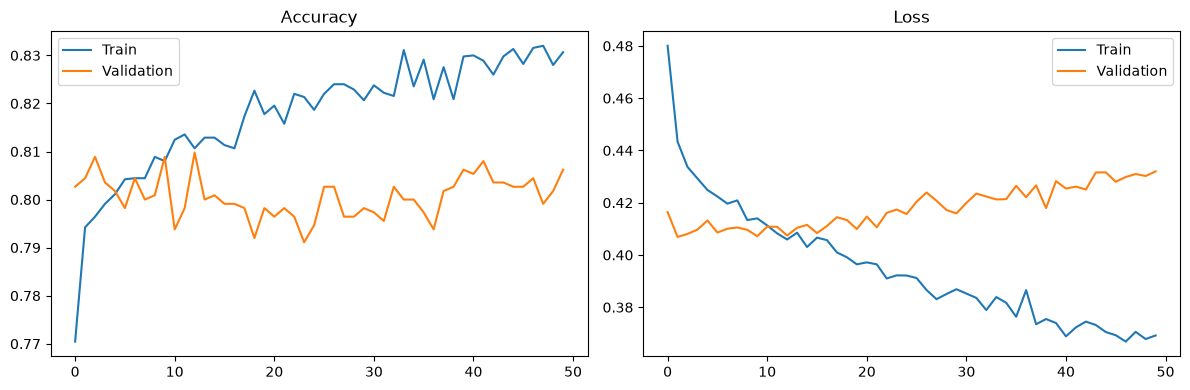

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].legend()
axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].legend()
plt.tight_layout()
plt.show()

### 3.2.17–3.2.18 — Individual prediction and ROC-AUC

**Reconstructed from the report's descriptions:** the code for these steps was not printed in the source document.

Individual churn probability: 0.18%
ROC-AUC: 0.820


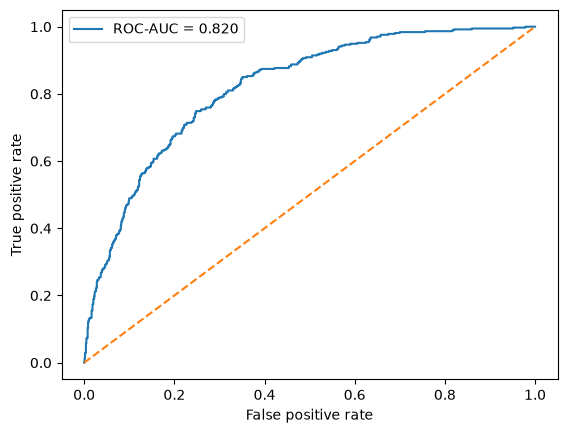

In [16]:
from sklearn.metrics import roc_curve, auc

sample = X_test.iloc[[0]]
sample_processed = preprocessor.transform(sample)
if sparse.issparse(sample_processed):
    sample_processed = sample_processed.toarray()
probability = float(model.predict(sample_processed, verbose=0).ravel()[0])
print(f"Individual churn probability: {probability:.2%}")

fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob.ravel())
roc_auc = auc(fpr, tpr)
print(f"ROC-AUC: {roc_auc:.3f}")
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.show()

### 3.2.19–3.2.20 — Save model and business risk tier

**Reconstructed from the report's descriptions.** The original report saved to `.h5`; `.keras` is used here as a documented modern-format substitution.

In [17]:
model.save("churn_model.keras")

def churn_risk_tier(prob):
    if prob > 0.7:
        return "High Risk"
    if prob > 0.4:
        return "Medium Risk"
    return "Low Risk"

print(churn_risk_tier(probability))

Low Risk


## Notes on results and reproducibility

The original academic report cites a **test accuracy of 78.46%** and **ROC-AUC around 0.82**. These are *reported historical results*, not results verified by running this reconstructed notebook. Retraining may produce different numbers because of random initialization, package versions, and data changes.

**Potential issues to review before publication:** model input shape and sparse/dense handling, data source availability, random seeds, and whether scaling should include other numeric dtypes. The report describes two predictive approaches in its introduction, but the practical code recovered here implements the **ANN** model; an additional baseline ML model has not been invented.
